# 05 Phase 4b and Phase 5: fine lambda stage, tuned JT, GRL rescue, H arms, post-hoc comparison

**Goal:** (4b-0) second application of the committed rule on 34 JT points; (4b-1) JT with the same Optuna budget as the other arms; (4b-2) extended GRL rescue; H1 to H3 (training for fairness, formula for calibration); Phase 5 comparison at the shared 10% flag rate and at matched fairness, with every arm labelled deployable (gender-blind at inference) or analysis only (uses gender).
Validation only, test set untouched. Mean over 3 seeds.

In [1]:
import json, sys, subprocess
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40); pd.set_option('display.max_rows', 200)
P4 = ROOT / Path((ROOT / 'artifacts' / 'phase4_rundir.txt').read_text().strip())
P4B = ROOT / Path((ROOT / 'artifacts' / 'phase4b_rundir.txt').read_text().strip())
P5 = P4B / 'phase5'; FIG = P5 / 'figures'; FIG.mkdir(exist_ok=True)
git = lambda *a: subprocess.run(['git', *a], cwd=ROOT, capture_output=True, text=True).stdout.strip()
print('phase4b run folder:', P4B.name)
print('rule file:', git('log', '--oneline', '-1', '--', 'configs/selection_rule.yaml'))
print('plan commits:', git('log', '--oneline', '--grep=phase4b', '-5'))

phase4b run folder: 20261101T092911Z_phase4b
rule file: f8189b2 specs: EOD-based selection rule; commit configs/selection_rule.yaml before any sweep
plan commits: 2ef4769 phase4b/5: pre-declare H1-H3 arms and Phase 5 comparison plan before running them
d2d54b0 phase4b-0: pre-declare fine lambda stage and second rule application before running
49d7c27 phase4b: pre-declare plan (JT tuning parity, extended GRL rescue, configurations-tried count) before any run


## 1. 4b-0: fine stage, rule applied a second time to the union of 34 JT points

In [2]:
sel = json.loads((P4 / 'fine_union' / 'selection_union.json').read_text())
u = pd.read_csv(P4 / 'fine_union' / 'sweep_points_union.csv')
print({k: sel[k] for k in ['application', 'n_points', 'step_used', 'n_feasible', 'ece_bound', 'soft_flag']})
print('winner:', sel['chosen']['name'], sel['chosen']['tag'])
fine = u[u.name == 'jt_fine'][['tag','auc_roc','auc_pr','eod','worst_group_ece','worst_group_ece_sd','dir','all_ok']]
pd.concat([u[(u.name == 'jt') & (u.tag == 'f0p05_c2_a0')][fine.columns], fine]).round(4).reset_index(drop=True)

{'application': 'second (union of main 20 + confusion 6 + fine 8 JT points)', 'n_points': 34, 'step_used': 'base rule', 'n_feasible': 4, 'ece_bound': 0.02, 'soft_flag': False}
winner: jt f0p05_c2_a0


,tag,auc_roc,auc_pr,eod,worst_group_ece,worst_group_ece_sd,dir,all_ok
0,f0p05_c2_a0,0.7428,0.2146,0.0234,0.0189,0.0058,0.9751,True
1,f0p02_c2_a0,0.7438,0.2141,0.0211,0.0261,0.0137,0.9794,False
2,f0p02_c4_a0,0.7384,0.2007,0.0349,0.0197,0.0074,0.9594,True
3,f0p02_c8_a0,0.7305,0.1895,0.0883,0.0167,0.0038,0.9289,False
4,f0p05_c4_a0,0.7362,0.1976,0.0278,0.0153,0.0015,0.9672,True
5,f0p05_c8_a0,0.7254,0.1848,0.0266,0.0217,0.0029,0.9680,False
6,f0p1_c2_a0,0.7397,0.2105,0.0236,0.0217,0.0053,0.9719,False
7,f0p1_c4_a0,0.7353,0.1989,0.0206,0.0142,0.0045,0.9767,True
8,f0p1_c8_a0,0.7235,0.1803,0.0372,0.0229,0.0025,0.9800,False


In [3]:
ok = u[u.all_ok][['name','tag','auc_roc','auc_pr','eod','worst_group_ece','dir']]
print('points passing the BASE rule (union of 34):'); ok.round(4)

points passing the BASE rule (union of 34):


,name,tag,auc_roc,auc_pr,eod,worst_group_ece,dir
7,jt,f0p05_c2_a0,0.7428,0.2146,0.0234,0.0189,0.9751
27,jt_fine,f0p02_c4_a0,0.7384,0.2007,0.0349,0.0197,0.9594
29,jt_fine,f0p05_c4_a0,0.7362,0.1976,0.0278,0.0153,0.9672
32,jt_fine,f0p1_c4_a0,0.7353,0.1989,0.0206,0.0142,0.9767


## 2. 4b-1: JT tuned with the same Optuna budget as the other arms (10 trials, 30% subsample, 8 epochs)

In [4]:
tu = json.loads((P4B / 'jt_tuning.json').read_text())
print('lambdas', tu['lambdas'], '| tuning schedule', tu['tune_schedule'], '| seconds', round(tu['seconds']))
pd.DataFrame({'untuned (A2 hp)': tu['untuned_hp (A2)'], 'tuned JT': tu['best_params']})

lambdas [0.05, 2.0, 0.0] | tuning schedule {'warmup_epochs': 2, 'ramp_epochs': 2} | seconds 91


,untuned (A2 hp),tuned JT
lr,0.002648,0.000711
weight_decay,0.000001,0.000711
dropout,0.253425,0.219598
emb_dim,16.000000,16.000000


In [5]:
t10 = pd.read_csv(P5 / 'table_10pct.csv')
def fmt(r, k): return f"{r[k]:.4f} [{r[k+'_lo']:.4f}, {r[k+'_hi']:.4f}]"
pick = t10[t10.arm.str.startswith('JT') | t10.arm.isin(['S1', 'S2-EG'])]
pd.DataFrame({'arm': pick.arm, 'deployable': pick.deployable,
              **{k: [fmt(r, k) for _, r in pick.iterrows()] for k in ['auc_roc','auc_pr','worst_group_ece','eod','dir','recall']}})

,arm,deployable,auc_roc,auc_pr,worst_group_ece,eod,dir,recall
1,S1,True,"0.7460 [0.7378, 0.7541]","0.2212 [0.2110, 0.2319]","0.0123 [0.0124, 0.0154]","0.0763 [0.0482, 0.1048]","0.9455 [0.9396, 0.9520]","0.3204 [0.3063, 0.3340]"
2,S2-EG,True,"0.7460 [0.7378, 0.7541]","0.2212 [0.2110, 0.2319]","0.0123 [0.0124, 0.0154]","0.0325 [0.0174, 0.0590]","0.9727 [0.9670, 0.9787]","0.3161 [0.3025, 0.3292]"
7,"JT chosen = JT-v1 (0.05,2,0)",True,"0.7428 [0.7345, 0.7508]","0.2146 [0.2047, 0.2251]","0.0189 [0.0180, 0.0200]","0.0234 [0.0141, 0.0501]","0.9751 [0.9694, 0.9808]","0.3097 [0.2954, 0.3227]"
8,"JT tuned (0.05,2,0)",True,"0.7415 [0.7328, 0.7491]","0.2132 [0.2030, 0.2237]","0.0252 [0.0241, 0.0265]","0.0121 [0.0103, 0.0353]","0.9802 [0.9745, 0.9861]","0.3085 [0.2942, 0.3215]"


In [6]:
pdiff = pd.read_csv(P5 / 'paired_diffs.csv')
J, T = 'JT chosen = JT-v1 (0.05,2,0)', 'JT tuned (0.05,2,0)'
print('Paired bootstrap, tuned JT minus S2-EG, and tuned minus untuned JT (95% CI):')
pd.concat([pdiff[(pdiff.A == T) & (pdiff.B == 'S2-EG')], pdiff[(pdiff.A == T) & (pdiff.B == J)]])[
    ['A','B','metric','diff_A_minus_B','ci_lo','ci_hi','significant']].round(4).reset_index(drop=True)

Paired bootstrap, tuned JT minus S2-EG, and tuned minus untuned JT (95% CI):


,A,B,metric,diff_A_minus_B,ci_lo,ci_hi,significant
0,"JT tuned (0.05,2,0)",S2-EG,auc_roc,-0.0046,-0.0062,-0.0031,True
1,"JT tuned (0.05,2,0)",S2-EG,auc_pr,-0.0080,-0.0115,-0.0044,True
2,"JT tuned (0.05,2,0)",S2-EG,worst_group_ece,0.0115,0.0094,0.0134,True
3,"JT tuned (0.05,2,0)",S2-EG,eod,-0.0158,-0.0311,0.0030,False
4,"JT tuned (0.05,2,0)",S2-EG,dir,0.0075,0.0046,0.0105,True
5,"JT tuned (0.05,2,0)",S2-EG,recall,-0.0075,-0.0138,-0.0008,True
6,"JT tuned (0.05,2,0)","JT chosen = JT-v1 (0.05,2,0)",auc_roc,-0.0013,-0.0027,-0.0000,True
7,"JT tuned (0.05,2,0)","JT chosen = JT-v1 (0.05,2,0)",auc_pr,-0.0013,-0.0040,0.0012,False
8,"JT tuned (0.05,2,0)","JT chosen = JT-v1 (0.05,2,0)",worst_group_ece,0.0063,0.0056,0.0069,True
9,"JT tuned (0.05,2,0)","JT chosen = JT-v1 (0.05,2,0)",eod,-0.0080,-0.0207,0.0046,False


## 3. 4b-2: extended GRL rescue (spec GRL, fairness and calibration terms off)

In [7]:
rs = json.loads((P4B / 'grl_rescue' / 'summary.json').read_text())
v = pd.DataFrame(rs['variants']); v['extra'] = v.extra.astype(str); v['seeds'] = v.seeds.astype(str)
print('criterion', rs['criterion'], '| compute hours', round(rs['hours'], 2))
v[['stage','lambda_a','extra','seeds','probe_mean','auc_roc_mean','probe_drop','auc_loss','works']].round(4)

criterion {'probe_drop': 0.03, 'auc_loss': 0.01} | compute hours 0.55


,stage,lambda_a,extra,seeds,probe_mean,auc_roc_mean,probe_drop,auc_loss,works
0,a_steps,0.05,{'adv_steps': 3},[0],0.7663,0.7473,0.0186,-0.0002,False
1,a_steps,0.10,{'adv_steps': 3},"[0, 1, 2]",0.7575,0.7462,0.0269,0.0003,False
2,a_steps,0.20,{'adv_steps': 3},[0],0.7662,0.7469,0.0187,0.0002,False
3,a_steps,0.50,{'adv_steps': 3},"[0, 1, 2]",0.7460,0.7448,0.0384,0.0018,True
4,a_steps,0.05,{'adv_steps': 5},[0],0.7707,0.7472,0.0141,-0.0002,False
5,a_steps,0.10,{'adv_steps': 5},"[0, 1, 2]",0.7488,0.7460,0.0357,0.0006,True
6,a_steps,0.20,{'adv_steps': 5},"[0, 1, 2]",0.7444,0.7461,0.0401,0.0004,True
7,a_steps,0.50,{'adv_steps': 5},"[0, 1, 2]",0.7410,0.7445,0.0435,0.0020,True
8,b_clip,0.05,{'adv_clip': 0.15345},[0],0.7731,0.7468,0.0118,0.0003,False
9,b_clip,0.10,{'adv_clip': 0.15345},[0],0.7814,0.7475,0.0035,-0.0004,False


In [8]:
att = pd.DataFrame(json.loads((P4B / 'grl_rescue' / 'attempts.json').read_text()))
print('control probe per seed:', att[att.stage == 'control'].set_index('seed').z_probe_lgbm_auc.round(4).to_dict())
att.groupby('stage').agg(attempts=('seed', 'size'), max_adv_loss=('max_train_adv_loss', 'max'),
                         min_auc_roc=('auc_roc', 'min')).round(3)

control probe per seed: {0: 0.7849, 1: 0.784, 2: 0.7845}


,attempts,max_adv_loss,min_auc_roc
stage,,,
a_steps,18,0.640,0.744
b_clip,14,0.649,0.744
c_ganin,4,8.920,0.742
control,3,0.000,0.746
d_smooth,8,0.667,0.745
e_combo,10,0.640,0.746


## 4. Phase 5 at the shared 10% flag rate (deployable = gender-blind at inference)

In [9]:
tbl = pd.DataFrame({'arm': t10.arm, 'deployable': t10.deployable,
                    **{k: [fmt(r, k) for _, r in t10.iterrows()] for k in ['auc_roc','auc_pr','worst_group_ece','eod','dir','recall']}})
tbl

,arm,deployable,auc_roc,auc_pr,worst_group_ece,eod,dir,recall
0,A2,True,"0.7460 [0.7378, 0.7541]","0.2212 [0.2110, 0.2319]","0.3502 [0.3473, 0.3530]","0.0763 [0.0482, 0.1048]","0.9455 [0.9396, 0.9520]","0.3204 [0.3063, 0.3340]"
1,S1,True,"0.7460 [0.7378, 0.7541]","0.2212 [0.2110, 0.2319]","0.0123 [0.0124, 0.0154]","0.0763 [0.0482, 0.1048]","0.9455 [0.9396, 0.9520]","0.3204 [0.3063, 0.3340]"
2,S2-EG,True,"0.7460 [0.7378, 0.7541]","0.2212 [0.2110, 0.2319]","0.0123 [0.0124, 0.0154]","0.0325 [0.0174, 0.0590]","0.9727 [0.9670, 0.9787]","0.3161 [0.3025, 0.3292]"
3,S2-GT,False,"0.7460 [0.7378, 0.7541]","0.2212 [0.2110, 0.2319]","0.0123 [0.0124, 0.0154]","0.0051 [0.0042, 0.0324]","0.9871 [0.9814, 0.9932]","0.3184 [0.3039, 0.3320]"
4,per-group Platt,False,"0.7466 [0.7384, 0.7544]","0.2216 [0.2118, 0.2323]","0.0057 [0.0067, 0.0110]","0.1410 [0.1121, 0.1685]","0.9133 [0.9074, 0.9197]","0.3198 [0.3065, 0.3336]"
5,per-group isotonic,False,"0.7446 [0.7363, 0.7523]","0.2196 [0.2097, 0.2305]","0.0056 [0.0068, 0.0106]","0.1561 [0.1283, 0.1828]","0.9058 [0.9000, 0.9120]","0.3180 [0.3047, 0.3310]"
6,fairlearn ThresholdOptimizer,False,"0.7460 [0.7378, 0.7541]","0.2212 [0.2110, 0.2319]","0.0123 [0.0124, 0.0154]","0.0015 [0.0039, 0.0315]","0.9826 [0.9709, 0.9949]","0.6750 [0.6600, 0.6882]"
7,"JT chosen = JT-v1 (0.05,2,0)",True,"0.7428 [0.7345, 0.7508]","0.2146 [0.2047, 0.2251]","0.0189 [0.0180, 0.0200]","0.0234 [0.0141, 0.0501]","0.9751 [0.9694, 0.9808]","0.3097 [0.2954, 0.3227]"
8,"JT tuned (0.05,2,0)",True,"0.7415 [0.7328, 0.7491]","0.2132 [0.2030, 0.2237]","0.0252 [0.0241, 0.0265]","0.0121 [0.0103, 0.0353]","0.9802 [0.9745, 0.9861]","0.3085 [0.2942, 0.3215]"
9,H1 (f=0.05)+S1,True,"0.7408 [0.7325, 0.7487]","0.2094 [0.1999, 0.2200]","0.0261 [0.0257, 0.0288]","0.0069 [0.0059, 0.0289]","0.9875 [0.9819, 0.9935]","0.3041 [0.2899, 0.3170]"


In [10]:
d = pdiff[pdiff.A == J][['B','metric','diff_A_minus_B','ci_lo','ci_hi','significant']]
print('Paired bootstrap difference, JT chosen minus each comparator (10% flag rate):')
d.pivot(index='B', columns='metric', values='diff_A_minus_B').round(4)

Paired bootstrap difference, JT chosen minus each comparator (10% flag rate):


metric,auc_pr,auc_roc,dir,eod,recall,worst_group_ece
B,,,,,,
A2,-0.0067,-0.0032,0.0296,-0.0500,-0.0107,-0.3312
H1 (f=0.05)+S1,0.0051,0.0020,-0.0123,0.0123,0.0056,-0.0082
H2 (f=0.10)+S1,0.0220,0.0099,-0.0110,-0.0001,0.0275,-0.0243
H3 (f=0.25)+S1,0.0450,0.0283,-0.0153,0.0138,0.0593,-0.0459
"JT tuned (0.05,2,0)",0.0013,0.0013,-0.0051,0.0080,0.0012,-0.0063
S1,-0.0067,-0.0032,0.0296,-0.0500,-0.0107,0.0052
S2-EG,-0.0067,-0.0032,0.0024,-0.0078,-0.0064,0.0052
S2-GT,-0.0067,-0.0032,-0.0120,0.0134,-0.0087,0.0052
fairlearn ThresholdOptimizer,-0.0067,-0.0032,-0.0074,0.0138,-0.3656,0.0052


In [11]:
print('Significant (95% CI excludes 0) differences, JT chosen minus comparator:')
d[d.significant].round(4).reset_index(drop=True)

Significant (95% CI excludes 0) differences, JT chosen minus comparator:


,B,metric,diff_A_minus_B,ci_lo,ci_hi,significant
0,A2,auc_roc,-0.0032,-0.0049,-0.0016,True
1,A2,auc_pr,-0.0067,-0.0102,-0.0033,True
2,A2,worst_group_ece,-0.3312,-0.3342,-0.3280,True
3,A2,eod,-0.0500,-0.0650,-0.0301,True
4,A2,dir,0.0296,0.0270,0.0324,True
5,A2,recall,-0.0107,-0.0168,-0.0040,True
6,S1,auc_roc,-0.0032,-0.0049,-0.0016,True
7,S1,auc_pr,-0.0067,-0.0102,-0.0033,True
8,S1,worst_group_ece,0.0052,0.0032,0.0070,True
9,S1,eod,-0.0500,-0.0650,-0.0301,True


In [12]:
h = pdiff[pdiff.A.str.startswith('H') & (pdiff.B == 'S2-EG')]
print('Each H arm minus S2-EG (deployable vs deployable):')
h.pivot(index='A', columns='metric', values='diff_A_minus_B').round(4)

Each H arm minus S2-EG (deployable vs deployable):


metric,auc_pr,auc_roc,dir,eod,recall,worst_group_ece
A,,,,,,
H1 (f=0.05)+S1,-0.0118,-0.0053,0.0147,-0.0201,-0.0119,0.0133
H2 (f=0.10)+S1,-0.0287,-0.0131,0.0134,-0.0077,-0.0338,0.0294
H3 (f=0.25)+S1,-0.0517,-0.0315,0.0177,-0.0217,-0.0657,0.0511


## 5. Matched fairness (target = EOD of JT chosen)

In [13]:
mt = pd.read_csv(P5 / 'table_matched.csv')
print('target EOD:', round(json.loads((P5 / 's1_note.json').read_text())['targets']['eod_target'], 4))
mt[['arm','deployable','knob','flag_rate','eod','eod_gap_to_target','matched(|gap|<=0.005)','recall','precision','auc_pr','worst_group_ece','dir']].round(4)

target EOD: 0.0234


,arm,deployable,knob,flag_rate,eod,eod_gap_to_target,matched(|gap|<=0.005),recall,precision,auc_pr,worst_group_ece,dir
0,A2,True,none (10% flag rate),0.0999,0.0763,0.0529,False,0.3204,0.2589,0.2212,0.3502,0.9455
1,S1,True,none (10% flag rate),0.0999,0.0763,0.0529,False,0.3204,0.2589,0.2212,0.0123,0.9455
2,A2 @ flag rate 5%,True,flag rate,0.0495,0.0550,0.0316,False,0.1883,0.3073,0.2212,0.3502,0.9691
3,S1 @ flag rate 5%,True,flag rate,0.0495,0.0550,0.0316,False,0.1883,0.3073,0.2212,0.0123,0.9691
4,S2-EG eps=0.08,True,EG eps,0.0999,0.0320,0.0087,False,0.3161,0.2556,0.2212,0.0123,0.9724
5,S2-EG eps=0.01 (Phase 2 default),True,EG eps,0.0999,0.0325,0.0091,False,0.3161,0.2555,0.2212,0.0123,0.9727
6,S2-GT (threshold fraction t),False,group-threshold fraction,0.0998,0.0236,0.0002,True,0.3170,0.2563,0.2212,0.0123,0.9719
7,"S2-GT (full, EOD minimised)",False,none,0.1004,0.0051,-0.0182,False,0.3184,0.2560,0.2212,0.0123,0.9871
8,per-group Platt,False,none (as fitted),0.0999,0.1410,0.1176,False,0.3198,0.2585,0.2216,0.0057,0.9133
9,per-group isotonic,False,none (as fitted),0.0999,0.1561,0.1328,False,0.3180,0.2571,0.2196,0.0056,0.9058


In [14]:
eg = pd.read_csv(P5 / 'eg_eps_curve.csv'); fr = pd.read_csv(P5 / 'flagrate_curve.csv')
print('S2-EG: EOD barely moves with eps (cannot reach the target):'); print(eg[['eps','eod','recall','flag_rate']].round(4).to_string(index=False))
print('S1 vs flag rate:'); fr[['rate','eod','recall','precision']].round(4).iloc[::4]

S2-EG: EOD barely moves with eps (cannot reach the target):
  eps    eod  recall  flag_rate
0.002 0.0328  0.3162     0.0999
0.005 0.0323  0.3162     0.0998
0.010 0.0325  0.3161     0.0999
0.020 0.0321  0.3161     0.0999
0.040 0.0323  0.3169     0.0998
0.080 0.0320  0.3161     0.0999
S1 vs flag rate:


,rate,eod,recall,precision
0,0.05,0.0550,0.1883,0.3073
4,0.09,0.0716,0.2952,0.2656
8,0.13,0.0881,0.3837,0.2388
12,0.17,0.1059,0.4599,0.2190
16,0.21,0.1122,0.5203,0.2003
20,0.25,0.1144,0.5737,0.1855


In [15]:
pm = pd.read_csv(P5 / 'paired_diffs_matched.csv')
print('Paired differences at the matched settings (JT chosen minus comparator):')
pm[pm.A == 'JT chosen'].pivot_table(index='B', columns='metric', values='diff_A_minus_B').round(4)

Paired differences at the matched settings (JT chosen minus comparator):


metric,auc_pr,auc_roc,dir,eod,recall,worst_group_ece
B,,,,,,
S1 @ 5%,-0.0067,-0.0032,0.0061,-0.0287,0.1213,0.0052
S2-EG matched,-0.0067,-0.0032,0.0027,-0.0079,-0.0064,0.0052
S2-GT matched,-0.0067,-0.0032,0.0032,-0.0007,-0.0072,0.0052


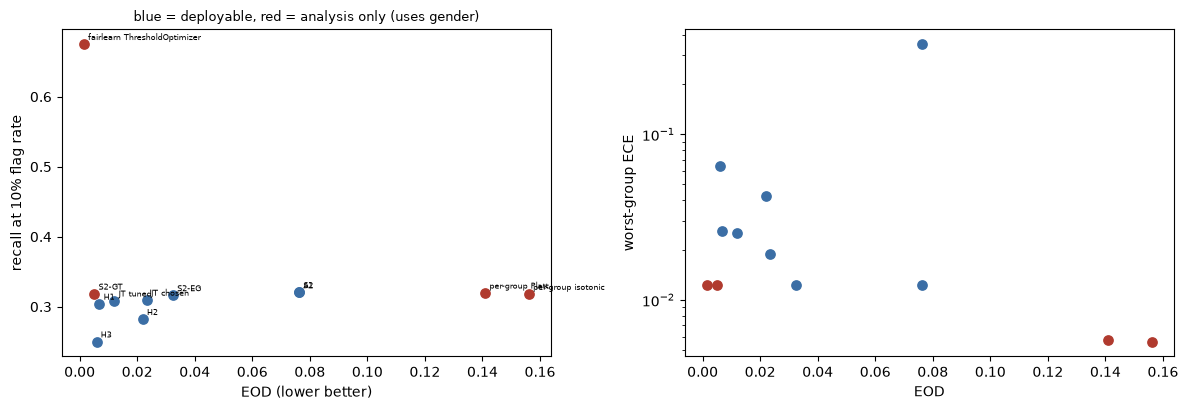

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
col = {True: '#3b6ea5', False: '#b03a2e'}
for _, r in t10.iterrows():
    ax[0].scatter(r.eod, r.recall, color=col[r.deployable], s=45)
    ax[0].annotate(r.arm.split(' (')[0].split(' =')[0], (r.eod, r.recall), fontsize=6, xytext=(3, 3), textcoords='offset points')
    ax[1].scatter(r.eod, r.worst_group_ece, color=col[r.deployable], s=45)
ax[0].set_xlabel('EOD (lower better)'); ax[0].set_ylabel('recall at 10% flag rate')
ax[1].set_xlabel('EOD'); ax[1].set_ylabel('worst-group ECE'); ax[1].set_yscale('log')
ax[0].set_title('blue = deployable, red = analysis only (uses gender)', fontsize=9)
plt.tight_layout(); plt.savefig(FIG / 'posthoc_scatter.png', dpi=150); plt.show()

## 6. Why S1 repairs calibration exactly while the learned calibration term is only approximate

In [17]:
n = json.loads((P5 / 's1_note.json').read_text())
print('class weights', n['class_weights'], '-> logit offset log(w1/w0) =', round(n['prior_shift_logit'], 4))
print({k: round(v, 4) for k, v in n.items() if k.endswith('worst_group_ece') and isinstance(v, float)})
print('H arms (training for fairness, then the S1 formula):', {k: round(v, 4) for k, v in n['H_worst_group_ece'].items()})
pd.DataFrame(n['lambda_c_curve_at_lambda_f_0']).rename(columns={'lambda_c': 'lambda_c (lambda_f = 0)'})

class weights {'0': 0.5439085896794473, '1': 6.193646774472003} -> logit offset log(w1/w0) = 2.4325
{'A2_worst_group_ece': 0.3502, 'S1_worst_group_ece': 0.0123, 'JT_worst_group_ece': 0.0189, 'JT_tuned_worst_group_ece': 0.0252}
H arms (training for fairness, then the S1 formula): {'H1 (f=0.05)+S1': 0.0261, 'H2 (f=0.10)+S1': 0.0423, 'H3 (f=0.25)+S1': 0.0645}


,lambda_c (lambda_f = 0),worst_group_ece,ece,cal_slope,cal_intercept
0,0.0,0.3545,0.3344,0.9954,-2.3896
1,0.5,0.1419,0.1387,0.8269,-1.4823
2,1.0,0.0717,0.0639,0.8718,-0.9115
3,2.0,0.0291,0.0243,1.0351,-0.2471


## 7. 4b-3: configurations tried per arm (for the paper's disclosure)

In [18]:
P2 = ROOT / 'artifacts' / 'runs' / '20261101T055729Z_phase2'
rows = []
for a in sorted(p.name for p in P2.iterdir() if (p / 'tuning.json').exists()):
    rows.append({'arm': a, 'optuna trials': len(json.loads((P2 / a / 'tuning.json').read_text())['trials'])})
rows.append({'arm': 'JT tuned (4b-1)', 'optuna trials': len(tu['trials'])})
pd.DataFrame(rows)

,arm,optuna trials
0,a0,10
1,a1,10
2,a1b,10
3,a2,10
4,a3,10
5,a4,10
6,a5,10
7,g1,10
8,JT tuned (4b-1),10


In [19]:
cnt = {name: len(list((P4 / name).glob('*/'))) for name in ['jt', 'jt_conf', 'abl_conf', 'jt_fine']}
att4 = json.loads((P4 / 'adversary_rescue' / 'attempts.json').read_text())
att4b = json.loads((P4B / 'grl_rescue' / 'attempts.json').read_text())
var4b = {(a['stage'], a['lambda_a'], json.dumps(a['extra'], sort_keys=True)) for a in att4b if a['stage'] != 'control'}
pd.Series({
    'JT lambda points, main sweep (5 x 4)': cnt['jt'],
    'JT lambda points, confusion adversary extra sweep': cnt['jt_conf'],
    'JT lambda points, fine stage 4b-0': cnt['jt_fine'],
    'JT lambda points, ablation-only': cnt['abl_conf'],
    'JT lambda points compared by the rule (union)': int(len(u)),
    'H arms (lambda_f values)': 3,
    'smoke/diagnostic configurations (4 + 3 + 2)': 9,
    'Phase 4 adversary rescue variants (a, b, c)': len(att4) - 1,
    '4b-2 GRL rescue variants (distinct, seed 0 first)': len({v for v in var4b}),
    '4b-2 GRL rescue runs including extra seeds': len(att4b),
    'S2-EG eps values refit (Phase 5)': 6,
    'S2-EG implementations tried (Phase 2: v1 unmatched, final)': 2,
}).to_frame('count')

,count
"JT lambda points, main sweep (5 x 4)",20
"JT lambda points, confusion adversary extra sweep",6
"JT lambda points, fine stage 4b-0",8
"JT lambda points, ablation-only",2
JT lambda points compared by the rule (union),34
H arms (lambda_f values),3
smoke/diagnostic configurations (4 + 3 + 2),9
"Phase 4 adversary rescue variants (a, b, c)",10
"4b-2 GRL rescue variants (distinct, seed 0 first)",32
4b-2 GRL rescue runs including extra seeds,57


## 8. Test set untouched

In [20]:
log = (ROOT / 'artifacts/guard/test_access.jsonl').read_text().strip().splitlines()
print(len(log), 'guard-log entry:', json.loads(log[0]).get('purpose'))
assert len(log) == 1 and json.loads(log[0]).get('purpose') == 'leakage_probe_gender_only'
print('selection rule last changed in:', git('log', '--oneline', '-1', '--', 'configs/selection_rule.yaml'))

1 guard-log entry: leakage_probe_gender_only
selection rule last changed in: f8189b2 specs: EOD-based selection rule; commit configs/selection_rule.yaml before any sweep


## What this shows

- **Fine stage (4b-0):** the committed rule, applied a second time to 34 JT points, picks the same point as the first application, (lambda_f, lambda_c, lambda_a) = (0.05, 2, 0). Larger lambda_c (4, 8) lowers worst-group ECE further but costs AUC-PR (0.201 and below against 0.215), so they do not win under "maximise AUC-PR". There is no JT-v1 versus JT-chosen split to report.
- **Tuning parity (4b-1):** with A2's Optuna budget, JT gets different hyper-parameters (lr 0.0007 instead of 0.0026). Tuned JT has a lower EOD (0.012) but a worse worst-group ECE (0.025, above the 0.02 bound of the committed rule) and about 0.001 lower AUC-ROC. The rule is not re-applied; the untuned point stays the chosen one and the tuned row is reported next to it. Tuned JT is further from S2-EG on ranking and calibration than the untuned JT.
- **GRL rescue (4b-2):** the spec GRL did not fail for every variant. With several head updates per trunk update (variant a) it is stable (adversary loss stays below 1) and lowers gender recoverability from z by 0.036 to 0.044 AUC at lambda_a 0.1 to 0.5 for at most 0.002 AUC-ROC (3 seeds). Clipping, the Ganin schedule and label smoothing alone did not reach the 0.03 criterion. Earlier "GRL failed" is therefore narrowed to "a single head update per trunk update fails". This was judged only on a fresh LightGBM probe of z at lambda_f = lambda_c = 0; no GRL point has been crossed with fairness or calibration, so it plays no role in the selected JT.
- **Phase 5, 10% flag rate:** JT does not beat S2-EG on ranking (AUC-ROC -0.003, AUC-PR -0.007) or on worst-group ECE (+0.005); its EOD advantage over S2-EG (-0.008) is not statistically distinguishable from zero. Per-group Platt/isotonic (analysis only) fix calibration but raise EOD to 0.14 to 0.16. The fairlearn ThresholdOptimizer reaches EOD 0.0015 only by flagging 34% of applicants (not rate-matched).
- **Matched fairness:** S2-EG (deployable) cannot move its EOD below about 0.032 through eps, so it cannot reach JT's 0.023; S2-GT (analysis only) can, at the same ranking quality as S1, i.e. higher AUC-PR than JT. A2 and S1 reach 0.055 at the lowest flag rate in the grid (5%) and not the target.
- **H arms:** training for fairness then applying the S1 formula gives low EOD but not the calibration the formula repairs on A2: worst-group ECE 0.026 (H1), 0.042 (H2), 0.065 (H3) against 0.012 for S1. Each H arm is significantly worse than S2-EG on AUC-ROC, AUC-PR, recall and worst-group ECE. The prior-shift offset (2.43 logits) is exact only if the fairness term leaves the logit distribution alone, which it does not.
- **Why S1 is exact and the learned term is not:** weighted CE adds a constant logit offset log(w1/w0) = 2.43, and S1 subtracts exactly that; no fitting is involved. The learned term minimises a soft, batch-binned ECE surrogate against other terms: at lambda_c = 2 worst-group ECE is 0.029 (0.019 together with the fairness term), never at S1's 0.012, and the error stays 1.5 to 2.4 times S1's.
- **Limits:** validation only, and the same validation split picks JT's lambdas and compares the arms, so JT's numbers are slightly optimistic, S2-EG's are not. Matched-fairness operating points are chosen on validation EOD. Platt/isotonic use cross-fitting inside validation. The test set is untouched.
